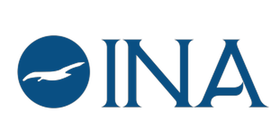

**Instituto Nuevos Aires**

# Trabajo Práctico N° 2

**Desarrollo de un sistema de Inteligencia Artificial para la predicción de abandono de clientes (Customer Churn)**

| Estudiante | Lucas Pérez Amador |
|---|---|
| Carrera | Tecnicatura Superior en Ciencia de Datos e Inteligencia Artificial |
| Materia | Desarrollo de Sistemas de Inteligencia Artificial (2.º cuatrimestre 2026) |
| Docente | MSc. Ángel Daniel Fuentes S. |
| Algoritmo | Regresión Logística |
| Dataset | Telco Customer Churn (Kaggle) |
| Fecha de entrega | 30 de octubre de 2026 |

---

## Aprendizaje Automático - Supervisado - Clasificación
## Algoritmo: Regresión Logística

| | |
|---|---|
| **Fuente de datos** | Kaggle — https://www.kaggle.com/datasets/blastchar/telco-customer-churn |
| **Archivo utilizado** | `Telco_Customer_Churn.csv` (descargado como `WA_Fn-UseC_-Telco-Customer-Churn.csv` y renombrado) |
| **Variable objetivo** | `Churn` → Yes = el cliente abandonó · No = el cliente permaneció |

> Para ejecutar: el dataset está en `data/Telco_Customer_Churn.csv` (ruta relativa `../data/`). Abrir este notebook desde la carpeta `notebooks/` y ejecutar todas las celdas en orden.

## 1. Importación de librerías

In [2]:
# Librería para trabajar datos en formato de tabla, Columnas, Filas etc.:
import pandas as pd
# Librería para realizar gráficos:
import matplotlib.pyplot as plt
# Para conformar nuestro modelo:
from sklearn.linear_model import LogisticRegression
# Librería que nos permite escalar los datos:
from sklearn.preprocessing import StandardScaler
# Método para poder ejecutar múltiples acciones a la vez, en la creación del modelo:
from sklearn.pipeline import make_pipeline
# Método que nos ayuda a separar los datos de Entrenamiento y Prueba:
from sklearn.model_selection import train_test_split
# Métodos que nos ayudan a realizar la evaluación de nuestro modelo:
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, classification_report

# Colores de los gráficos
COLOR_NO = '#11740e'   # verde: cliente que permanece
COLOR_SI = '#c0392b'   # rojo: cliente que abandona
print('Librerías importadas de forma correcta')

Librerías importadas de forma correcta


## 2. Carga del dataset (Etapa 1)

In [5]:
# Carga de datos - dataset
df = pd.read_csv('../data/Telco_Customer_Churn.csv')
print('Datos cargados de forma correcta')
print('Primeros 5 registros de nuestro dataset')
display(df.head())

Datos cargados de forma correcta
Primeros 5 registros de nuestro dataset


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Exploración de los datos (Etapa 1)

### 3.1 Cantidad de filas y columnas

In [7]:
print('Cantidad de filas (clientes): ', df.shape[0])
print('Cantidad de columnas (variables): ', df.shape[1])

Cantidad de filas (clientes):  7043
Cantidad de columnas (variables):  21


### 3.2 Tipos de datos

In [8]:
# Tipos de datos de cada columna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

`TotalCharges` es un importe, pero figura como texto y no como número: se revisa en el punto siguiente.

### 3.3 Valores faltantes

In [12]:
# Valores faltantes por columna
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [13]:
# TotalCharges es texto: lo convertimos a número para detectar valores vacíos
total_numerico = pd.to_numeric(df['TotalCharges'], errors='coerce')
print('Valores vacíos en TotalCharges: ', total_numerico.isnull().sum())
display(df.loc[total_numerico.isnull(), ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

Valores vacíos en TotalCharges:  11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


`isnull().sum()` no muestra nulos, pero `TotalCharges` tiene **11 valores vacíos** (un espacio en blanco). Los 11 son clientes con `tenure = 0`: todavía no tuvieron facturación.

### 3.4 Clientes que abandonaron y que permanecieron

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Porcentaje (%):
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


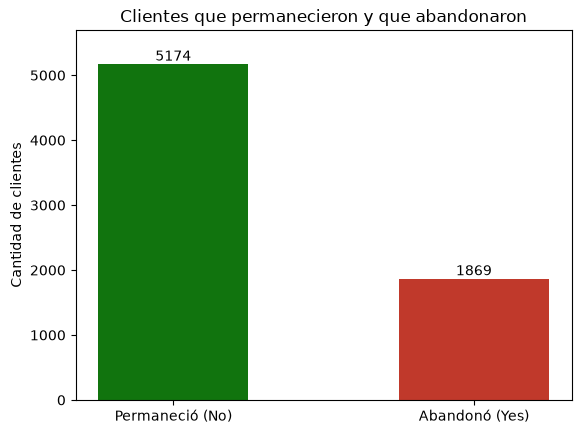

In [14]:
# Distribución de la variable objetivo
print(df['Churn'].value_counts())
print()
print('Porcentaje (%):')
print((df['Churn'].value_counts(normalize=True) * 100).round(2))

conteo = df['Churn'].value_counts()
barras = plt.bar(['Permaneció (No)', 'Abandonó (Yes)'], [conteo['No'], conteo['Yes']],
                 color=[COLOR_NO, COLOR_SI], width=0.5)
plt.bar_label(barras)
plt.ylim(0, conteo.max() * 1.1)
plt.title('Clientes que permanecieron y que abandonaron')
plt.ylabel('Cantidad de clientes')
plt.show()

### 3.5 Relación de las variables con el abandono

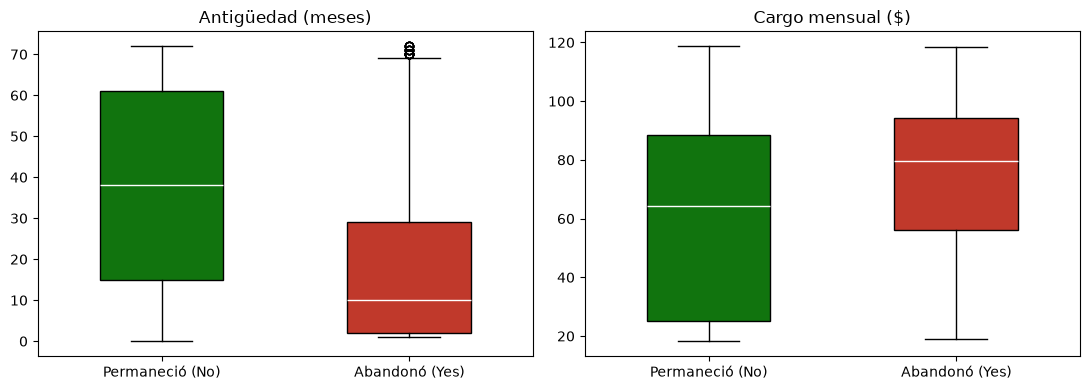

In [15]:
# Variables numéricas según abandono
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for eje, columna, titulo in zip(ejes, ['tenure', 'MonthlyCharges'], ['Antigüedad (meses)', 'Cargo mensual ($)']):
    cajas = eje.boxplot([df.loc[df['Churn'] == 'No', columna], df.loc[df['Churn'] == 'Yes', columna]],
                        patch_artist=True, widths=0.5)
    eje.set_xticks([1, 2], ['Permaneció (No)', 'Abandonó (Yes)'])
    for caja, color in zip(cajas['boxes'], [COLOR_NO, COLOR_SI]):
        caja.set_facecolor(color)
    for mediana in cajas['medians']:
        mediana.set_color('white')
    eje.set_title(titulo)
plt.tight_layout()
plt.show()

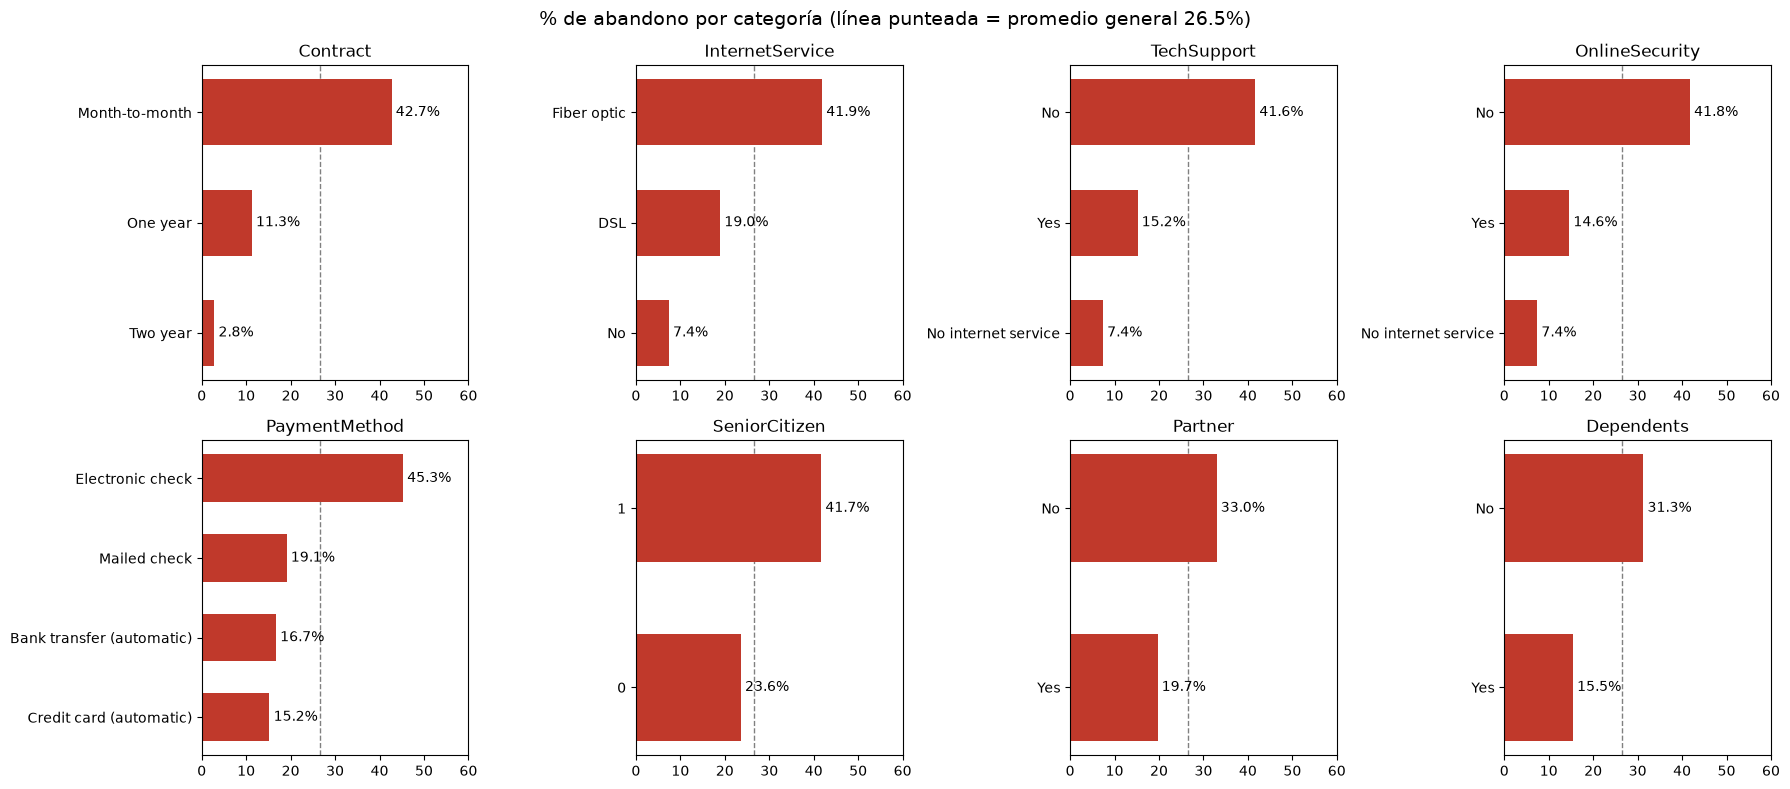

In [16]:
# Porcentaje de abandono dentro de cada categoría
tasa_global = (df['Churn'] == 'Yes').mean() * 100
variables_a_explorar = ['Contract', 'InternetService', 'TechSupport', 'OnlineSecurity',
                        'PaymentMethod', 'SeniorCitizen', 'Partner', 'Dependents']

fig, ejes = plt.subplots(2, 4, figsize=(18, 8))
for eje, variable in zip(ejes.flatten(), variables_a_explorar):
    tasa = df.groupby(variable)['Churn'].apply(lambda s: (s == 'Yes').mean() * 100).sort_values()
    barras = eje.barh(tasa.index.astype(str), tasa.values, color=COLOR_SI, height=0.6)
    eje.bar_label(barras, fmt='%.1f%%', padding=3)
    eje.axvline(tasa_global, color='gray', linestyle='--', linewidth=1, zorder=0)
    eje.set_title(variable)
    eje.set_xlim(0, 60)
plt.suptitle(f'% de abandono por categoría (línea punteada = promedio general {tasa_global:.1f}%)', fontsize=14)
plt.tight_layout()
plt.show()

### 3.6 Observaciones iniciales
- **7.043 clientes y 21 columnas.** No hay nulos explícitos, pero sí **11 vacíos ocultos** en `TotalCharges`.
- **Clases desbalanceadas:** 73,46 % permanece y 26,54 % abandona. Un modelo que diga siempre "No" acertaría el 73,46 %: ese es el piso a superar.
- Quienes abandonan llevan **menos tiempo** en la empresa y pagan **más por mes**.
- El abandono es mayor con **contrato mes a mes** (42,7 % vs. 2,8 % en dos años), **fibra óptica**, **sin soporte técnico ni seguridad en línea** y **pago con cheque electrónico**.

## 4. Preparación de las variables (Etapa 2)

### 4.1 Selección de variables
Se utilizan las **11 variables propuestas** por la consigna, porque todas muestran diferencias en el porcentaje de abandono . **`customerID` no se utiliza:** es un identificador y no permite generalizar el comportamiento a clientes nuevos.

In [17]:
# Variables seleccionadas
variables_numericas = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
variables_categoricas = ['Contract', 'InternetService', 'TechSupport', 'OnlineSecurity',
                         'PaymentMethod', 'Partner', 'Dependents']

### 4.2 Tratamiento de valores faltantes

In [18]:
# Copia de los datos para no modificar el dataset original
datos = df.copy()

# TotalCharges: de texto a número. Los 11 vacíos son clientes con tenure = 0 (sin facturación)
datos['TotalCharges'] = pd.to_numeric(datos['TotalCharges'], errors='coerce').fillna(0)
print('Valores faltantes en TotalCharges: ', datos['TotalCharges'].isnull().sum())

# 'No internet service' significa que no tiene el servicio 
for columna in ['TechSupport', 'OnlineSecurity']:
    datos[columna] = datos[columna].replace('No internet service', 'No')

Valores faltantes en TotalCharges:  0


### 4.3 Separación de nuestras variables
- **X**: variables predictoras - características
- **y**: variable objetivo

In [24]:
# Variables predictoras 
X = datos[variables_numericas + variables_categoricas]
# Variable objetivo: 1 = abandonó (Yes) - 0 = no abandonó (No)
y = datos['Churn'].map({'No': 0, 'Yes': 1})
print('Variables en X ', X.shape)
print('Variable objetivo: ', y.shape)

Variables en X  (7043, 11)
Variable objetivo:  (7043,)


### 4.4 Conversión de variables categóricas a números
El modelo trabaja solo con números: cada categoría se convierte en una columna 0/1. Con `drop_first=True` la primera categoría de cada variable queda como referencia.

In [25]:
# Convertir las variables categóricas (texto) en columnas 0/1
X = pd.get_dummies(X, columns=variables_categoricas, drop_first=True, dtype=int)
print('Variables en X luego de codificar: ', X.shape)
display(X.head())

Variables en X luego de codificar:  (7043, 15)


,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Contract_One year,Contract_Two year,InternetService_Fiber optic,InternetService_No,TechSupport_Yes,OnlineSecurity_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,Partner_Yes,Dependents_Yes
0,1,29.85,29.85,0,0,0,0,0,0,0,0,1,0,1,0
1,34,56.95,1889.50,0,1,0,0,0,0,1,0,0,1,0,0
2,2,53.85,108.15,0,0,0,0,0,0,1,0,0,1,0,0
3,45,42.30,1840.75,0,1,0,0,0,1,1,0,0,0,0,0
4,2,70.70,151.65,0,0,0,1,0,0,0,0,1,0,0,0


In [22]:
# Revisión final: valores faltantes y tipos de datos
print('Valores faltantes en X: ', X.isnull().sum().sum())
print(X.dtypes.value_counts())

Valores faltantes en X:  0
int64      13
float64     2
Name: count, dtype: int64


## 5. Separación de entrenamiento y prueba (Etapa 2)
- 80 % para entrenar al modelo
- 20 % para realizar pruebas al modelo

In [26]:
# Dividir los datos en Entrenamiento y Prueba
X_entrenamiento, X_prueba, y_entrenamiento, y_prueba = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)
print(f'Registros utilizados para el entrenamiento:  {len(X_entrenamiento)}')
print(f'Registros utilizados para las pruebas:  {len(X_prueba)}')

Registros utilizados para el entrenamiento:  5634
Registros utilizados para las pruebas:  1409


## 6. Construcción del modelo (Etapa 3)

| Parámetro | Valor | Para qué sirve |
|---|---|---|
| `StandardScaler()` | — | Escala las variables (media 0, desvío 1) para que todas pesen igual en el modelo. |
| `make_pipeline` | — | Une el escalado y el modelo: el escalado se calcula solo con los datos de entrenamiento. |
| `max_iter` | 1000 | Cantidad máxima de iteraciones para encontrar los coeficientes del modelo. |
| Umbral (por defecto) | 0,5 | Si la probabilidad de abandono es ≥ 0,5, el modelo predice "abandona". |

In [28]:
modelo = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)
print('Modelo creado de forma correcta')

Modelo creado de forma correcta


## 7. Entrenamiento (Etapa 3)

In [29]:
modelo.fit(X_entrenamiento, y_entrenamiento)
print('¡Modelo entrenado de forma correcta!')

¡Modelo entrenado de forma correcta!


## 8. Predicciones (Etapa 3)

In [30]:
# Comprobando el aprendizaje del modelo con los datos de prueba
prediccion = modelo.predict(X_prueba)
# Probabilidad de abandono de cada cliente
probabilidad = modelo.predict_proba(X_prueba)[:, 1]

display(pd.DataFrame({
    'Clase real': y_prueba,
    'Clase predicha': prediccion,
    'Probabilidad de abandono': probabilidad.round(3)
}).head(10))

,Clase real,Clase predicha,Probabilidad de abandono
437,0,0,0.039
2280,0,1,0.578
2235,0,0,0.063
4460,0,1,0.533
3761,0,0,0.019
5748,0,1,0.537
3568,0,0,0.439
2976,0,0,0.085
5928,0,0,0.004
1639,1,0,0.451


## 9. Evaluación (Etapas 4 y 5)

### 9.1 Exactitud (Accuracy)

In [31]:
# Evaluación del modelo - accuracy_score
exactitud = accuracy_score(y_prueba, prediccion)
print(f'Exactitud en prueba:  {round(exactitud * 100, 2)}%')
print(f'Aciertos:  {(prediccion == y_prueba).sum()} de {len(y_prueba)} clientes')

# Exactitud con los datos de entrenamiento, para detectar sobreajuste
exactitud_entrenamiento = accuracy_score(y_entrenamiento, modelo.predict(X_entrenamiento))
print(f'Exactitud en entrenamiento:  {round(exactitud_entrenamiento * 100, 2)}%')

# Línea base: un modelo que responde siempre "No abandona"
print(f'Línea base (siempre "No"):  {round((y_prueba == 0).mean() * 100, 2)}%')

Exactitud en prueba:  79.84%
Aciertos:  1125 de 1409 clientes
Exactitud en entrenamiento:  79.84%
Línea base (siempre "No"):  73.46%


- El modelo clasifica bien al **79,84 %** de los clientes que no vio durante el entrenamiento (1.125 de 1.409).
- Supera en 6,4 puntos a la línea base (73,46 %).
- La exactitud en entrenamiento es la misma: **no hay sobreajuste**.
- Como solo el 26,5 % abandona, el accuracy no alcanza para saber si detecta bien a quienes se van: se revisa con la matriz de confusión.

### 9.2 Prueba e interpretación con registros de prueba (Etapa 5)
Se toma un acierto y un error de cada clase del conjunto de prueba.

In [33]:
resultados = pd.DataFrame({
    'Clase real': y_prueba.map({0: 'No abandonó', 1: 'Abandonó'}),
    'Clase predicha': pd.Series(prediccion, index=y_prueba.index).map({0: 'No abandonó', 1: 'Abandonó'}),
    'Prob. abandono': probabilidad.round(2)
})
resultados['Resultado'] = (y_prueba == prediccion).map({True: 'CORRECTA', False: 'INCORRECTA'})

# Primer registro de cada caso: acierto y error en cada clase
registros = [
    resultados[(y_prueba == 1) & (prediccion == 1)].index[0],
    resultados[(y_prueba == 0) & (prediccion == 0)].index[0],
    resultados[(y_prueba == 1) & (prediccion == 0)].index[0],
    resultados[(y_prueba == 0) & (prediccion == 1)].index[0],
]
columnas = ['tenure', 'MonthlyCharges', 'Contract', 'InternetService', 'TechSupport', 'PaymentMethod']
display(datos.loc[registros, columnas].join(resultados.loc[registros]))

,tenure,MonthlyCharges,Contract,InternetService,TechSupport,PaymentMethod,Clase real,Clase predicha,Prob. abandono,Resultado
3524,11,84.80,Month-to-month,Fiber optic,No,Credit card (automatic),Abandonó,Abandonó,0.62,CORRECTA
437,72,114.05,Two year,Fiber optic,Yes,Credit card (automatic),No abandonó,No abandonó,0.04,CORRECTA
1639,17,45.05,Month-to-month,DSL,No,Electronic check,Abandonó,No abandonó,0.45,INCORRECTA
2280,8,100.15,Month-to-month,Fiber optic,Yes,Credit card (automatic),No abandonó,Abandonó,0.58,INCORRECTA


| Registro | Interpretación |
|---|---|
| **3524** | Correcta. Cliente nuevo, mes a mes, fibra óptica y sin soporte: perfil de riesgo. |
| **437** | Correcta. 72 meses y contrato de dos años: riesgo muy bajo. |
| **1639** | Incorrecta (falso negativo). Su probabilidad (0,45) quedó apenas debajo del umbral de 0,5. |
| **2280** | Incorrecta (falso positivo). Tiene el perfil típico de abandono, pero se quedó. |

### 9.3 Errores del modelo - Abandonos detectados y no detectados

In [ ]:
print('Abandonaron y el modelo predijo que NO:', ((y_prueba == 1) & (prediccion == 0)).sum())
print('No abandonaron y el modelo predijo que SÍ:', ((y_prueba == 0) & (prediccion == 1)).sum())
print('Abandonos detectados:', ((y_prueba == 1) & (prediccion == 1)).sum(), 'de', (y_prueba == 1).sum())

Abandonaron y el modelo predijo que NO: 171
No abandonaron y el modelo predijo que SÍ: 113
Abandonos detectados: 203 de 374


## 10. Conclusiones (Etapa 6)

1. **¿Qué problema resolví?** Clasificar a los clientes de una empresa de telecomunicaciones en *abandonó* / *no abandonó* a partir de sus datos históricos.
2. **¿Qué algoritmo seleccioné y por qué?** Regresión Logística con `StandardScaler`: estima la probabilidad de abandono, sus coeficientes muestran qué características se relacionan con el abandono y obtuvo la mejor exactitud frente a KNN y Árbol de decisión.
3. **¿Qué variables utilicé y por qué?** Las 11 propuestas (`tenure`, `MonthlyCharges`, `TotalCharges`, `SeniorCitizen`, `Contract`, `InternetService`, `TechSupport`, `OnlineSecurity`, `PaymentMethod`, `Partner`, `Dependents`), porque todas muestran diferencias en el porcentaje de abandono. Se excluyó `customerID`.
4. **¿Qué resultados obtuve?** Exactitud de **79,84 %** en prueba, por encima de la línea base (73,46 %) y sin sobreajuste. Mayor riesgo: clientes nuevos, contrato mes a mes, fibra óptica, sin soporte ni seguridad y pago con cheque electrónico.
5. **¿Qué errores cometió el modelo?** 284 errores sobre 1.409 clientes de prueba (1.409 − 1.125 aciertos): 171 clientes abandonaron y el modelo predijo que se quedaban (el error más costoso), y 113 se quedaron y el modelo predijo que abandonaban. Detecta 203 de los 374 clientes que abandonan (54 %).
6. **¿Qué limitaciones identifiqué?** Clases desbalanceadas, `tenure` y `TotalCharges` muy relacionadas, el modelo solo capta relaciones lineales, faltan datos como satisfacción o reclamos, y se evaluó con una única división 80/20.